# Análisis exploratorio de datos

Contentesta las siguientes preguntas escribiendo el código de Python necesario para encontrar las respuestas o producir las gráficas necesarias

---


In [84]:
# No mostrar advertencias
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/retailmax.csv')

### 1. ¿Cuál es la distribución de edades de los clientes?
- **Objetivo**: Comprender la distribución de las edades en el conjunto de datos.
- **Respuesta esperada**: Un histograma de la columna Age.

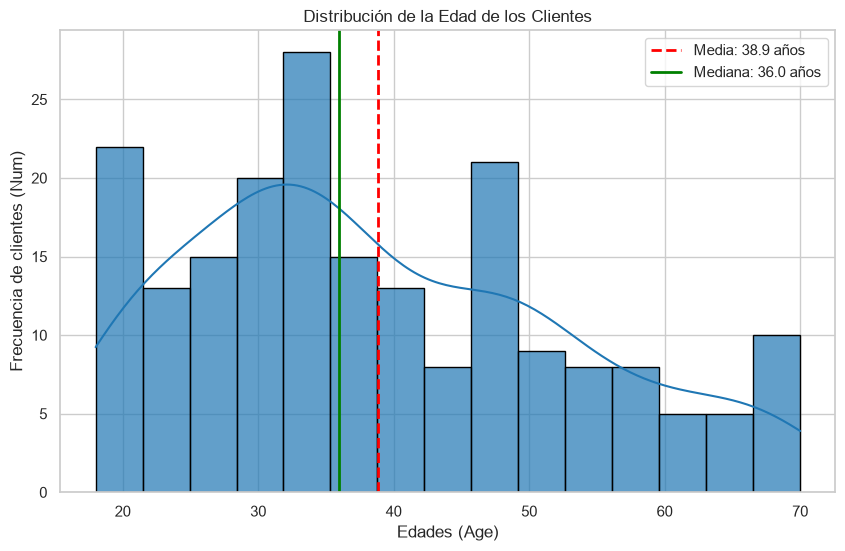

In [85]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=15, kde=True, color= "#1f77b4", edgecolor='black', alpha=0.7)
plt.title('Distribución de la Edad de los Clientes', fontsize=12)
plt.xlabel('Edades (Age)')
plt.ylabel('Frecuencia de clientes (Num)')
plt.axvline(df['Age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Media: {df["Age"].mean():.1f} años')
plt.axvline(df['Age'].median(), color='green', linestyle='-', linewidth=2, label=f'Mediana: {df["Age"].median():.1f} años')
plt.legend(fontsize=11)
plt.show()


### 2. ¿Existen diferencias significativas en los ingresos anuales entre hombres y mujeres?
- **Objetivo**: Comparar la distribución de ingresos anuales entre géneros.
- **Respuesta esperada**: Una gráfica de cajas (boxplot) que muestre la distribución de Annual Income (k$) por género.

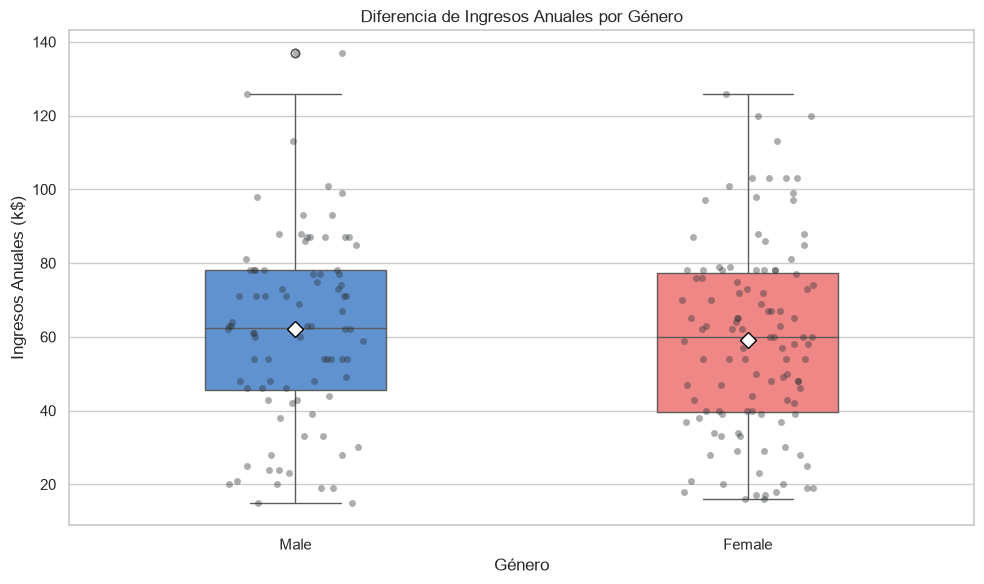

In [86]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Gender", y="Annual Income (k$)", palette={'Male': '#4e90e2', 'Female': '#ff7675'}, width=0.4, showmeans=True, meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 8})
sns.stripplot(data=df, x="Gender", y="Annual Income (k$)", color="#2D3436", alpha=0.4, jitter=0.15, size=5)

plt.title('Diferencia de Ingresos Anuales por Género')
plt.xlabel('Género')
plt.ylabel('Ingresos Anuales (k$)')
plt.tight_layout()
plt.show()


### 3. ¿Cómo se distribuye la puntuación de gasto (Spending Score) entre los diferentes rangos de edad?
- **Objetivo**: Analizar la relación entre la edad y la puntuación de gasto.
- **Respuesta esperada**: Una gráfica de dispersión (scatter plot) o un gráfico de cajas que compare la Spending Score (1-100) con diferentes grupos de edad.

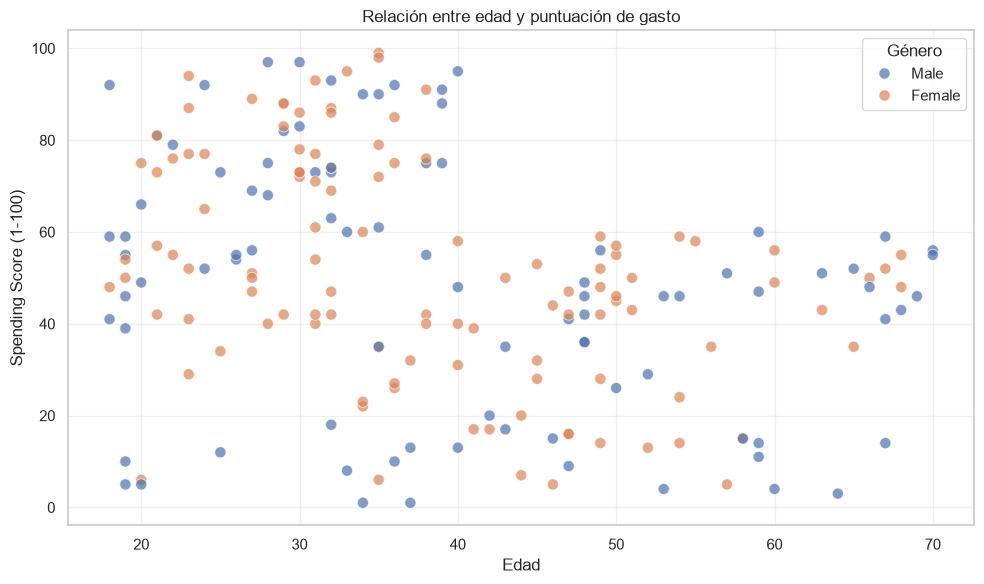

In [87]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Spending Score (1-100)',
    hue='Gender',
    alpha=0.7,
    s=65
)

plt.title('Relación entre edad y puntuación de gasto')
plt.xlabel('Edad')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Género')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?
- **Objetivo**: Identificar si existe una relación lineal entre el ingreso y el gasto.
- **Respuesta esperada**: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

Coeficiente de correlación de Pearson: 0.0099


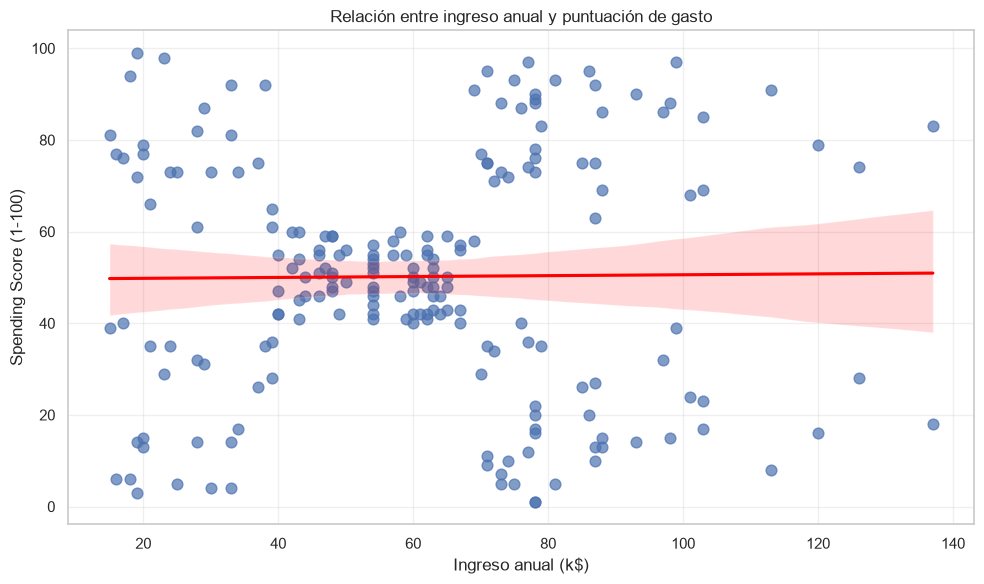

In [88]:
correlacion = df['Annual Income (k$)'].corr(
    df['Spending Score (1-100)']
)

print(f'Coeficiente de correlación de Pearson: {correlacion:.4f}')

# 3. Crear gráfica de dispersión
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    scatter_kws={'alpha': 0.7, 's': 60},
    line_kws={'color': 'red'}
)

plt.title('Relación entre ingreso anual y puntuación de gasto')
plt.xlabel('Ingreso anual (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?
- **Objetivo**: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.
- **Respuesta esperada**: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

                    count   mean  median    std  min  max
Income Group                                             
Bajo (15-40)           50  49.48    44.5  30.22    3   99
Medio (41-70)          76  50.68    50.0   8.47   29   91
Alto (71-100)          60  50.52    51.5  34.32    1   97
Muy alto (101-140)     14  48.79    48.0  31.62    8   91


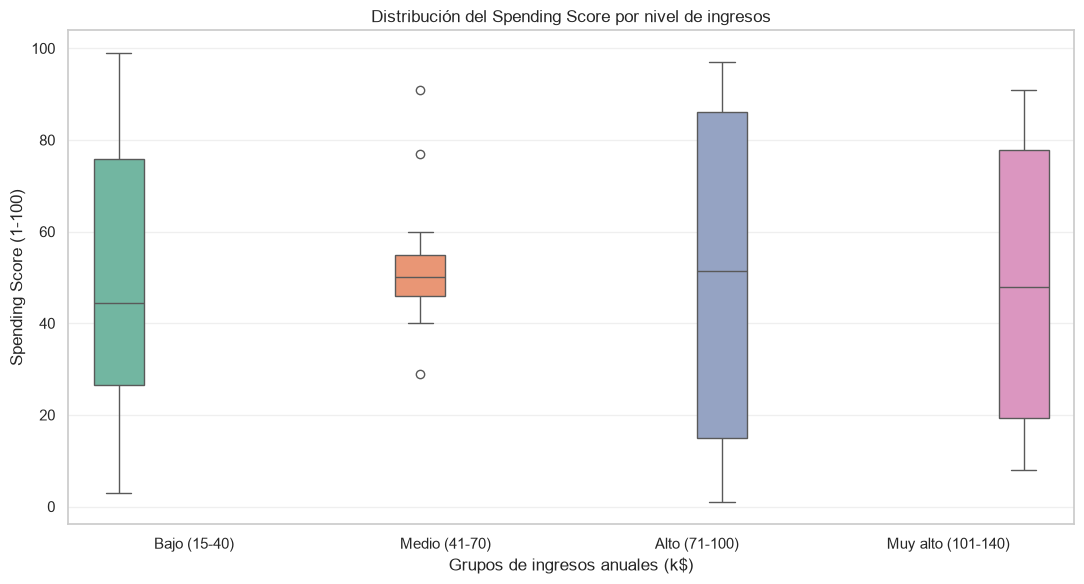

In [89]:
bins = [14, 40, 70, 100, 140]

labels = [
    'Bajo (15-40)',
    'Medio (41-70)',
    'Alto (71-100)',
    'Muy alto (101-140)'
]

df['Income Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=bins,
    labels=labels
)

resumen = df.groupby(
    'Income Group',
    observed=False
)['Spending Score (1-100)'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

print(resumen.round(2))

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='Income Group',
    y='Spending Score (1-100)',
    hue='Income Group',
    palette='Set2',
    legend=False
)

plt.title('Distribución del Spending Score por nivel de ingresos')
plt.xlabel('Grupos de ingresos anuales (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



### 6. ¿Cuál es la proporción de clientes por género?
- **Objetivo**: Determinar el balance de género en el conjunto de datos.
- **Respuesta esperada**: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

        Cantidad de clientes  Porcentaje (%)
Gender                                      
Female                   112            56.0
Male                      88            44.0


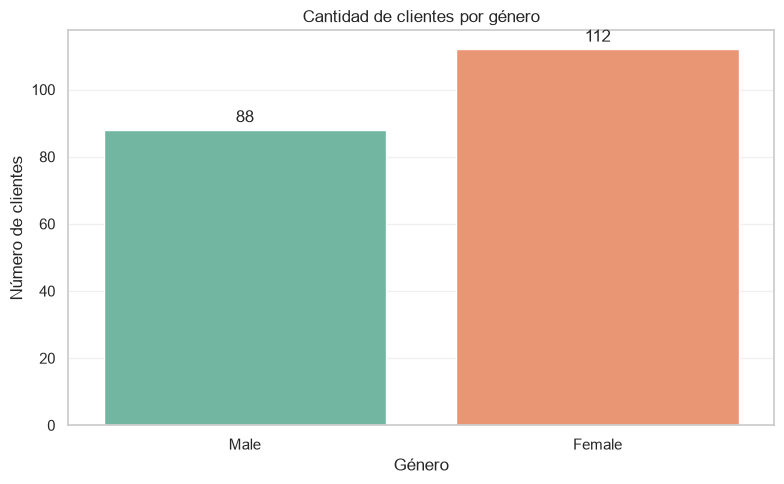

In [90]:
conteo_genero = df['Gender'].value_counts()

porcentaje_genero = df['Gender'].value_counts(normalize=True) * 100

resumen = pd.DataFrame({
    'Cantidad de clientes': conteo_genero,
    'Porcentaje (%)': porcentaje_genero
})

print(resumen.round(2))

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Gender',
    hue='Gender',
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Cantidad de clientes por género')
plt.xlabel('Género')
plt.ylabel('Número de clientes')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### 7. ¿Qué grupos de edad gastan más en promedio?
- **Objetivo**: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio.
- **Respuesta esperada**: Una gráfica de barras que compare la puntuación de gasto promedio entre diferentes grupos de edad.

  Age Group  Spending Score (1-100)
0     18-29                   58.58
1     30-39                   61.10
2     40-49                   34.95
3     50-59                   34.72
4     60-70                   43.00


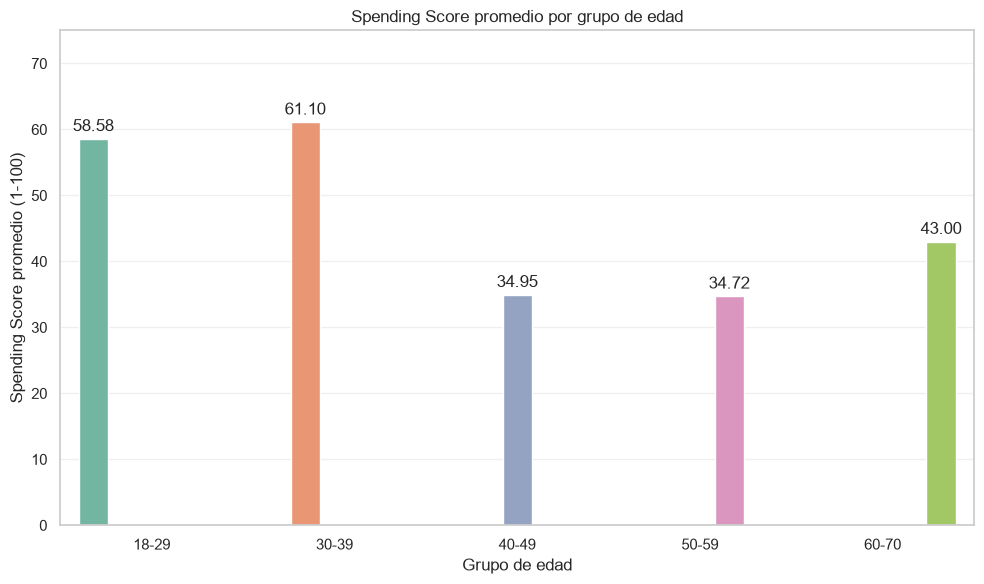

In [91]:
bins = [17, 29, 39, 49, 59, 70]
labels = ['18-29', '30-39', '40-49', '50-59', '60-70']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

promedio_gasto = df.groupby(
    'Age Group',
    observed=False
)['Spending Score (1-100)'].mean().reset_index()

print(promedio_gasto.round(2))

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=promedio_gasto,
    x='Age Group',
    y='Spending Score (1-100)',
    hue='Age Group',
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.title('Spending Score promedio por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Spending Score promedio (1-100)')
plt.ylim(0, 75)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?
- **Objetivo**: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.
- **Respuesta esperada**: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

Correlación entre edad e ingreso anual: -0.0124


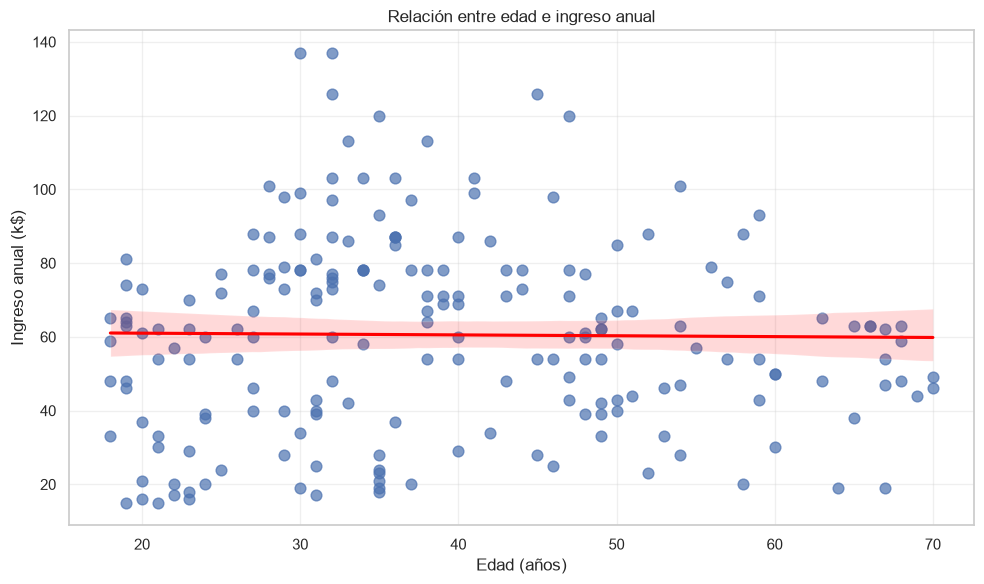

In [92]:
correlacion = df['Age'].corr(df['Annual Income (k$)'])

print(f'Correlación entre edad e ingreso anual: {correlacion:.4f}')

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    scatter_kws={'alpha': 0.7, 's': 60},
    line_kws={'color': 'red'}
)

plt.title('Relación entre edad e ingreso anual')
plt.xlabel('Edad (años)')
plt.ylabel('Ingreso anual (k$)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?
- **Objetivo**: Entender cómo se distribuyen estas dos variables en conjunto.
- **Respuesta esperada**: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

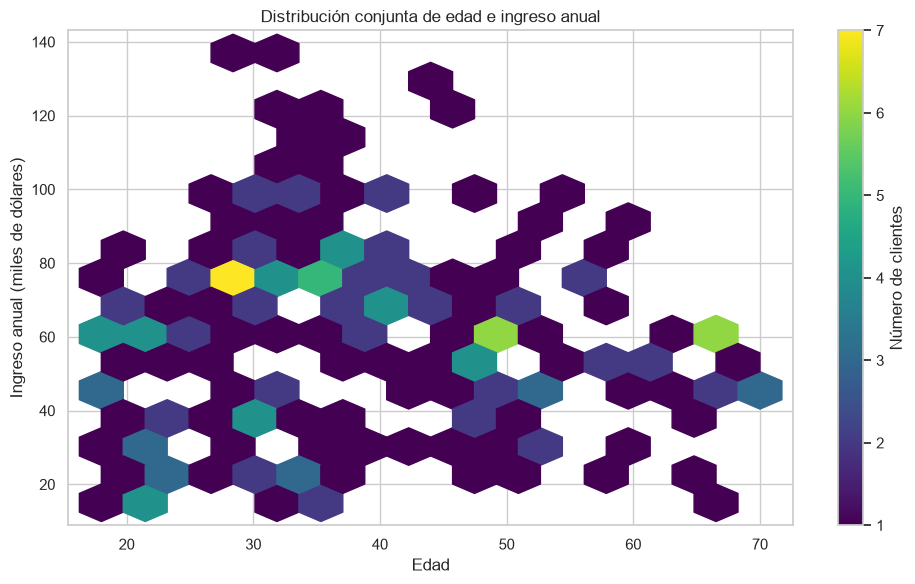

In [93]:
plt.figure(figsize=(10, 6))

plt.hexbin(
    df['Age'],
    df['Annual Income (k$)'],
    gridsize=15,
    cmap='viridis',
    mincnt=1
)

plt.colorbar(label='Número de clientes')
plt.title('Distribución conjunta de edad e ingreso anual')
plt.xlabel('Edad')
plt.ylabel('Ingreso anual (miles de dólares)')

plt.tight_layout()
plt.show()


### 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?
- **Objetivo**: Analizar la relación entre la puntuación de gasto y el género.
- **Respuesta esperada**: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

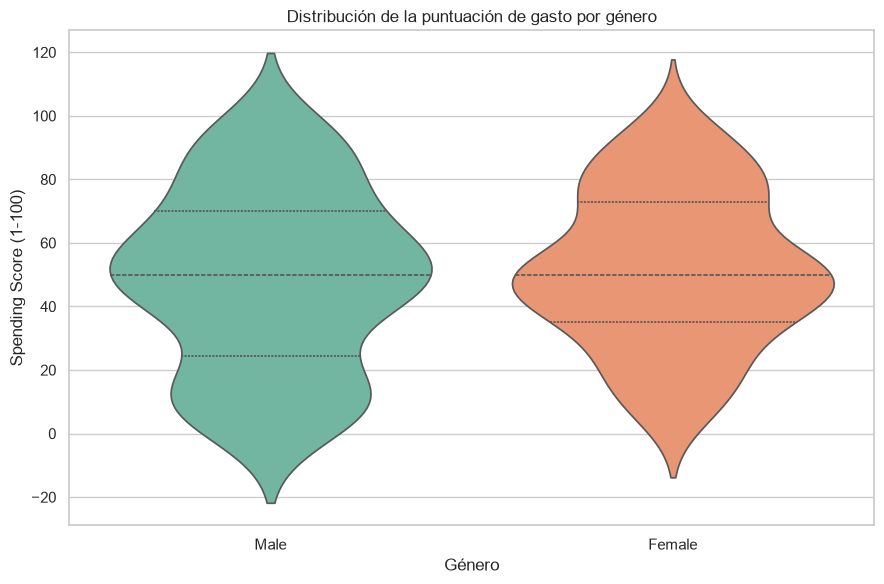

In [94]:
plt.figure(figsize=(9, 6))

sns.violinplot(
    data=df,
    x='Gender',
    y='Spending Score (1-100)',
    inner='quartile',
    palette='Set2'
)

plt.title('Distribución de la puntuación de gasto por género')
plt.xlabel('Género')
plt.ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()